# Diagnosis Kerusakan Bearing- Kasus 04

Klasifikasi empat kondisi bearing berdasarkan ringkasan getaran. Tahap kerja mencakup pengolahan data, pelatihan model, dan evaluasi.

## 1. Load Data
Dataset dibaca untuk melihat jumlah rekaman dan tipe data.

In [ ]:
from pathlib import Path
import shutil
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd() / 'BearingCare_Kasus04'
for subfolder in ('data', 'figures', 'artifacts'):
    (ROOT / subfolder).mkdir(parents=True, exist_ok=True)

target = ROOT / 'data' / 'raw.csv'

if not target.is_file():
    candidates = [Path.cwd() / 'raw.csv', Path('/content/raw.csv'),
                  Path('/content/BearingCare_Kasus04/data/raw.csv')]
    existing = next((p for p in candidates if p.is_file()), None)
    if existing:
        if existing.resolve() != target.resolve():
            shutil.copy2(existing, target)
    else:
        try:
            from google.colab import files
        except ImportError as exc:
            raise FileNotFoundError('Tempatkan raw.csv di folder notebook lalu jalankan ulang.') from exc
        uploaded = files.upload()
        if 'raw.csv' not in uploaded:
            raise FileNotFoundError('Harus mengunggah file bernama raw.csv (tanpa ZIP).')
        target.write_bytes(uploaded['raw.csv'])



Saving raw.csv to raw.csv


In [ ]:
raw = pd.read_csv(ROOT / 'data' / 'raw.csv')
print(f'Jumlah baris: {raw.shape[0]:,} | Jumlah kolom: {raw.shape[1]}')
display(raw.head())
print('\nTipe data:')
display(raw.dtypes.to_frame('tipe_data'))


Jumlah baris: 15,220 | Jumlah kolom: 14


,id_rekaman,posisi_sensor,kecepatan_rpm,beban_kN,suhu_housing_C,rms_g,puncak_g,kurtosis,crest_factor,energi_bpfo,energi_bpfi,energi_bsf,frekuensi_dominan_hz,kondisi
0,REC-06504,drive_end,2547.0,2.79,53.8,0.5168,1.1658,0.039,2.256,0.1400,0.0436,0.0629,40.9,NORMAL
1,REC-02314,drive_end,1824.0,0.54,47.9,0.3603,1.1888,2.109,3.300,0.1309,0.0031,0.1030,116.0,outer
2,REC-01359,drive_end,2865.0,3.72,53.7,0.6982,2.0926,1.224,2.997,0.1902,0.0680,0.1525,46.5,normal
3,REC-12268,drive_end,2796.0,1.15,51.8,0.4973,1.4369,2.706,2.890,0.0788,0.0662,0.0441,46.4,normal
4,REC-06543,fan_end,2419.0,2.09,55.3,0.5089,1.6455,2.894,3.234,0.0230,0.0045,0.1951,82.7,bola



Tipe data:


,tipe_data
id_rekaman,object
posisi_sensor,object
kecepatan_rpm,float64
beban_kN,float64
suhu_housing_C,float64
rms_g,float64
puncak_g,float64
kurtosis,float64
crest_factor,float64
energi_bpfo,float64


In [ ]:
print('Duplikat baris persis:', raw.duplicated().sum())
print('Duplikat ID rekaman:', raw['id_rekaman'].duplicated().sum())

audit_awal = pd.DataFrame({
    'nilai_hilang': raw.isna().sum(),
    'persen_hilang': (raw.isna().mean() * 100).round(2),
    'nilai_unik': raw.nunique(dropna=True)
})
display(audit_awal)
print('Variasi label sebelum dibersihkan:')
display(raw['kondisi'].value_counts().to_frame('jumlah'))


Duplikat baris persis: 220
Duplikat ID rekaman: 220


,nilai_hilang,persen_hilang,nilai_unik
id_rekaman,0,0.00,15000
posisi_sensor,0,0.00,2
kecepatan_rpm,0,0.00,1802
beban_kN,0,0.00,551
suhu_housing_C,153,1.01,256
rms_g,0,0.00,5205
puncak_g,0,0.00,10378
kurtosis,456,3.00,4035
crest_factor,0,0.00,2233
energi_bpfo,0,0.00,3066


Variasi label sebelum dibersihkan:


,jumlah
kondisi,
normal,7863
outer_race,2894
inner_race,2072
bola,1476
ok,164
NORMAL,154
Normal,150
outer,72
Outer Race,67


## 2. Exploratory Data Analysis (EDA)

Pemeriksaan awal mencakup data kosong, duplikasi, variasi label, dan sebaran nilai.

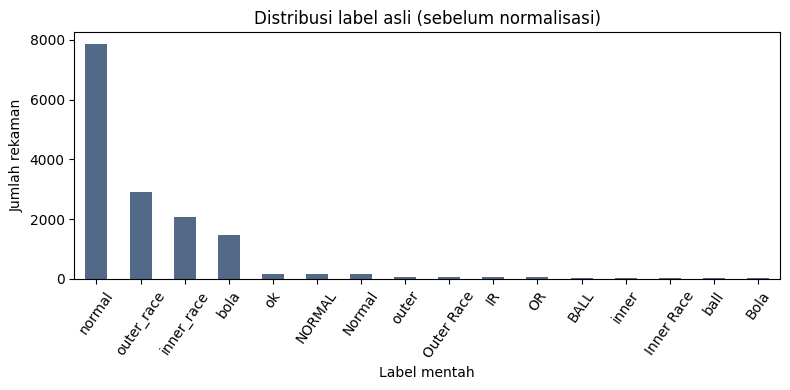

,count,mean,std,min,25%,50%,75%,max
kecepatan_rpm,15220.0,2090.959461,533.368985,0.0000,1644.000000,2095.50000,2546.000000,3000.0000
rms_g,15220.0,0.480142,0.147388,-0.9521,0.377300,0.46945,0.572625,1.0992
puncak_g,15220.0,1.611779,0.533721,0.4632,1.216675,1.54330,1.932200,4.3333
suhu_housing_C,15067.0,52.747946,4.218667,39.2000,49.800000,52.70000,55.600000,67.9000
kurtosis,14764.0,3.364824,0.967957,0.0330,2.698000,3.32850,3.988000,7.2270


In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
raw['kondisi'].value_counts().plot(kind='bar', ax=ax, color='#526988')
ax.set_title('Distribusi label asli (sebelum normalisasi)')
ax.set_xlabel('Label mentah')
ax.set_ylabel('Jumlah rekaman')
ax.tick_params(axis='x', rotation=55)
plt.tight_layout()
plt.show()

display(raw[['kecepatan_rpm', 'rms_g', 'puncak_g',
             'suhu_housing_C', 'kurtosis']].describe().T)


In [ ]:
alias_label = {
    'normal': 'normal', 'ok': 'normal',
    'outer_race': 'outer_race', 'outer': 'outer_race', 'or': 'outer_race',
    'inner_race': 'inner_race', 'inner': 'inner_race', 'ir': 'inner_race',
    'bola': 'bola', 'ball': 'bola'
}

clean = raw.drop_duplicates().copy()
label_asli = (clean['kondisi'].astype('string')
               .str.strip().str.lower()
               .str.replace(r'[\s-]+', '_', regex=True))
label_bersih = label_asli.map(alias_label)
if label_bersih.isna().any():
    raise ValueError('Label belum dikenal: ' + str(label_asli[label_bersih.isna()].unique()))

clean['kondisi'] = label_bersih.astype(str)
clean['posisi_sensor'] = clean['posisi_sensor'].astype('string').str.strip().str.lower()
labels = ['normal', 'outer_race', 'inner_race', 'bola']

print('Sebelum cleaning:', len(raw))
print('Setelah duplikat dihapus:', len(clean))
print('RPM <= 0:', int((clean['kecepatan_rpm'] <= 0).sum()))
print('RMS <= 0:', int((clean['rms_g'] <= 0).sum()))
print('Nilai suhu kosong:', int(clean['suhu_housing_C'].isna().sum()))
print('Nilai kurtosis kosong:', int(clean['kurtosis'].isna().sum()))
display(clean['kondisi'].value_counts().reindex(labels).to_frame('jumlah'))

clean.to_csv(ROOT / 'data' / 'clean.csv', index=False)


Sebelum cleaning: 15220
Setelah duplikat dihapus: 15000
RPM <= 0: 60
RMS <= 0: 45
Nilai suhu kosong: 150
Nilai kurtosis kosong: 450


,jumlah
kondisi,
normal,8219
outer_race,3039
inner_race,2178
bola,1564


## 3. Data Cleaning

Data duplikat dihapus dan penulisan label diseragamkan. Nilai yang tidak wajar turut diperiksa sebelum pemodelan.

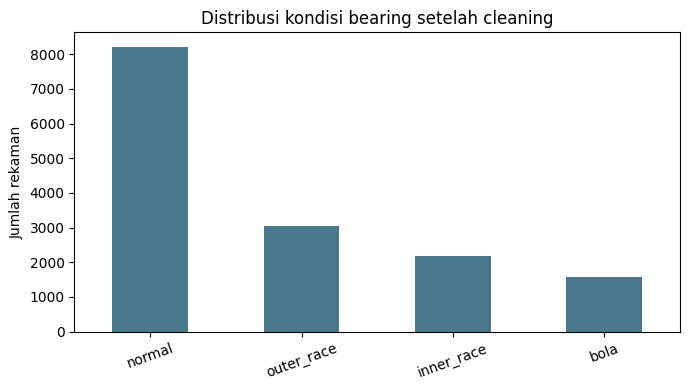

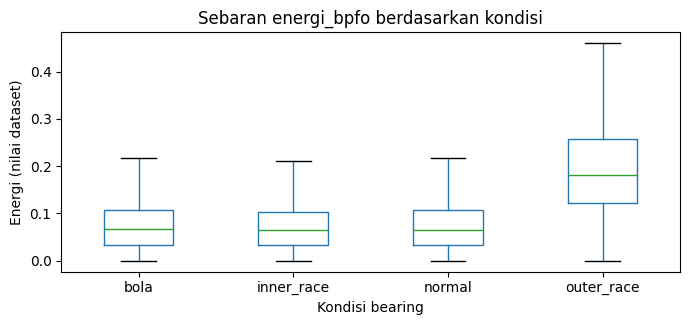

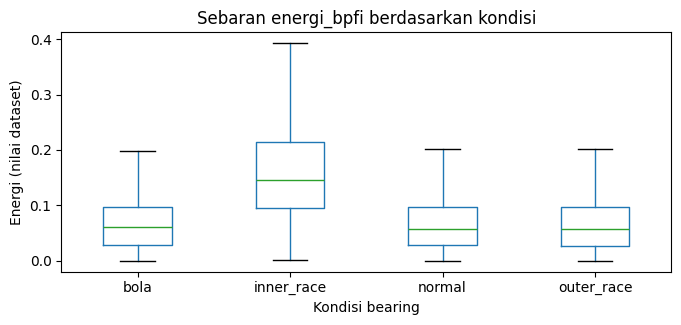

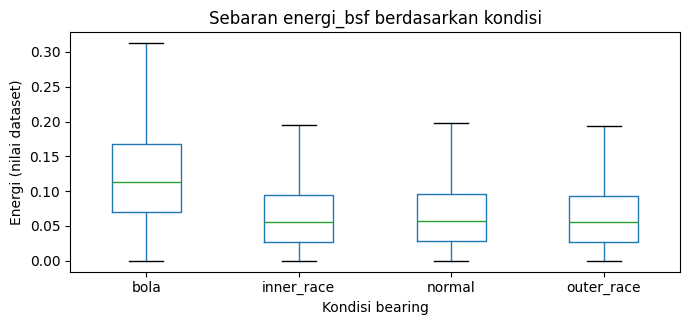

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
counts = clean['kondisi'].value_counts().reindex(labels)
counts.plot(kind='bar', ax=ax, color='#4a778b')
ax.set_title('Distribusi kondisi bearing setelah cleaning')
ax.set_ylabel('Jumlah rekaman')
ax.set_xlabel('')
ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
fig.savefig(ROOT / 'figures' / 'class_distribution.png', dpi=160)
plt.show()

for col in ['energi_bpfo', 'energi_bpfi', 'energi_bsf']:
    fig, ax = plt.subplots(figsize=(7, 3.5))
    clean.boxplot(column=col, by='kondisi', ax=ax, grid=False, showfliers=False)
    plt.suptitle('')
    ax.set_title(f'Sebaran {col} berdasarkan kondisi')
    ax.set_xlabel('Kondisi bearing')
    ax.set_ylabel('Energi (nilai dataset)')
    plt.tight_layout()
    plt.show()


In [ ]:
from sklearn.model_selection import train_test_split

train_val, test = train_test_split(
    clean, test_size=0.15, stratify=clean['kondisi'], random_state=42
)
train, valid = train_test_split(
    train_val, test_size=0.15 / 0.85,
    stratify=train_val['kondisi'], random_state=42
)

for name, part in [('Train', train), ('Validation', valid), ('Test', test)]:
    print(f'{name}: {len(part):,} baris ({len(part)/len(clean):.0%})')

assert set(train.id_rekaman).isdisjoint(valid.id_rekaman)
assert set(train.id_rekaman).isdisjoint(test.id_rekaman)
assert set(valid.id_rekaman).isdisjoint(test.id_rekaman)

display(pd.DataFrame({
    'train': train['kondisi'].value_counts(normalize=True),
    'validation': valid['kondisi'].value_counts(normalize=True),
    'test': test['kondisi'].value_counts(normalize=True)
}).reindex(labels).round(3))

for filename, part in [('train.csv', train), ('validation.csv', valid), ('test.csv', test)]:
    part.to_csv(ROOT / 'data' / filename, index=False)


Train: 10,500 baris (70%)
Validation: 2,250 baris (15%)
Test: 2,250 baris (15%)


,train,validation,test
kondisi,,,
normal,0.548,0.548,0.548
outer_race,0.203,0.203,0.203
inner_race,0.145,0.145,0.145
bola,0.104,0.104,0.104


## 4. Split Data

Data dibagi secara stratified menjadi 70% train, 15% validation, dan 15% test agar proporsi setiap kelas terjaga.

In [ ]:
import numpy as np
import pandas as pd

TARGET = "kondisi"
ID_COLUMN = "id_rekaman"
CATEGORY_COLUMN = "posisi_sensor"
NUMERIC_COLUMNS = [
    "kecepatan_rpm", "beban_kN", "suhu_housing_C", "rms_g", "puncak_g",
    "kurtosis", "crest_factor", "energi_bpfo", "energi_bpfi",
    "energi_bsf", "frekuensi_dominan_hz",
]
RAW_FEATURES = [CATEGORY_COLUMN, *NUMERIC_COLUMNS]
ENGINEERED_COLUMNS = [
    "energi_total", "rasio_bpfo", "rasio_bpfi", "rasio_bsf",
    "frekuensi_per_putaran", "puncak_dibagi_rms",
]
LABELS = ["normal", "outer_race", "inner_race", "bola"]
DISPLAY_LABELS = {
    "normal": "Normal", "outer_race": "Kerusakan cincin luar",
    "inner_race": "Kerusakan cincin dalam", "bola": "Kerusakan bola",
}
SPARE_PARTS = {
    "normal": "Tidak ada komponen yang perlu diganti berdasarkan prediksi ini; lanjutkan inspeksi berkala.",
    "outer_race": "Siapkan bearing pengganti dengan spesifikasi cincin luar yang sesuai dan perlengkapan pemasangan.",
    "inner_race": "Siapkan bearing pengganti sesuai ukuran cincin dalam/poros dan perlengkapan pemasangan.",
    "bola": "Siapkan bearing pengganti lengkap yang kompatibel dan perlengkapan pemasangan.",
}
ALIASES = {
    "normal": "normal", "ok": "normal",
    "outer_race": "outer_race", "outer": "outer_race", "or": "outer_race",
    "inner_race": "inner_race", "inner": "inner_race", "ir": "inner_race",
    "bola": "bola", "ball": "bola",
}

def normalize_labels(y: pd.Series) -> pd.Series:
    raw = y.astype("string").str.strip().str.lower().str.replace(r"[\s-]+", "_", regex=True)
    mapped = raw.map(ALIASES)
    bad = sorted(raw[mapped.isna()].dropna().unique().tolist())
    if bad:
        raise ValueError(f"Label target belum dikenal: {bad}")
    return mapped.astype(str)

def clean_dataset(df: pd.DataFrame) -> tuple[pd.DataFrame, dict]:
    missing = sorted(set(RAW_FEATURES + [ID_COLUMN, TARGET]) - set(df.columns))
    if missing:
        raise ValueError(f"Kolom data hilang: {missing}")
    before = len(df)
    out = df.drop_duplicates().copy()
    duplicate_count = before - len(out)
    out[TARGET] = normalize_labels(out[TARGET])
    out[CATEGORY_COLUMN] = out[CATEGORY_COLUMN].astype("string").str.strip().str.lower()
    problems = {
        "rows_raw": before,
        "exact_duplicates": duplicate_count,
        "rows_clean": len(out),
        "missing_suhu": int(out["suhu_housing_C"].isna().sum()),
        "missing_kurtosis": int(out["kurtosis"].isna().sum()),
        "rpm_zero_or_negative": int((pd.to_numeric(out["kecepatan_rpm"], errors="coerce") <= 0).sum()),
        "rms_zero_or_negative": int((pd.to_numeric(out["rms_g"], errors="coerce") <= 0).sum()),
        "unique_ids": int(out[ID_COLUMN].nunique()),
        "class_counts": out[TARGET].value_counts().to_dict(),
    }
    return out, problems

def prepare_features(df: pd.DataFrame, engineered: bool = False) -> pd.DataFrame:
    missing = sorted(set(RAW_FEATURES) - set(df.columns))
    if missing:
        raise ValueError(f"Kolom fitur hilang: {missing}")
    x = df[RAW_FEATURES].copy()
    x[CATEGORY_COLUMN] = x[CATEGORY_COLUMN].astype("string").str.strip().str.lower().fillna("unknown")
    x[CATEGORY_COLUMN] = x[CATEGORY_COLUMN].where(x[CATEGORY_COLUMN].isin(["drive_end", "fan_end"]), "unknown")
    for column in NUMERIC_COLUMNS:
        x[column] = pd.to_numeric(x[column], errors="coerce")
        x[column] = x[column].replace([np.inf, -np.inf], np.nan)

    x.loc[x["kecepatan_rpm"] <= 0, "kecepatan_rpm"] = np.nan
    x.loc[x["rms_g"] <= 0, "rms_g"] = np.nan
    for col in ["beban_kN", "puncak_g", "kurtosis", "crest_factor", "energi_bpfo", "energi_bpfi", "energi_bsf", "frekuensi_dominan_hz"]:
        x.loc[x[col] < 0, col] = np.nan
    if engineered:
        e = x["energi_bpfo"] + x["energi_bpfi"] + x["energi_bsf"]
        x["energi_total"] = e
        safe_e = e.replace(0, np.nan)
        x["rasio_bpfo"] = x["energi_bpfo"] / safe_e
        x["rasio_bpfi"] = x["energi_bpfi"] / safe_e
        x["rasio_bsf"] = x["energi_bsf"] / safe_e
        x["frekuensi_per_putaran"] = 60 * x["frekuensi_dominan_hz"] / x["kecepatan_rpm"]
        x["puncak_dibagi_rms"] = x["puncak_g"] / x["rms_g"]
        x = x.replace([np.inf, -np.inf], np.nan)
    return x


## 5. Baseline — Logistic Regression

Regresi logistik digunakan sebagai model awal dengan fitur asli. Penilaian menggunakan macro F1-score.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, accuracy_score
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier

X_train_base = prepare_features(train, engineered=False)
X_valid_base = prepare_features(valid, engineered=False)
y_train = train['kondisi']
y_valid = valid['kondisi']

preprocess_baseline = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median', keep_empty_features=True)),
        ('scaler', StandardScaler())
    ]), NUMERIC_COLUMNS),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False),
     ['posisi_sensor'])
], sparse_threshold=0)

baseline = Pipeline([
    ('preprocessor', preprocess_baseline),
    ('model', LogisticRegression(max_iter=1500, class_weight='balanced', random_state=42))
])
baseline.fit(X_train_base, y_train)
pred_base = baseline.predict(X_valid_base)

baseline_f1 = f1_score(y_valid, pred_base, average='macro', labels=labels, zero_division=0)
print(f'Macro F1 baseline (validation): {baseline_f1:.5f}')
print(f'Akurasi baseline (validation): {accuracy_score(y_valid, pred_base):.5f}')


Macro F1 baseline (validation): 0.68939
Akurasi baseline (validation): 0.74311


In [ ]:
X_train_tree = prepare_features(train, engineered=True)
X_valid_tree = prepare_features(valid, engineered=True)

print('Fitur baseline:', len(X_train_base.columns))
print('Fitur model pembanding:', len(X_train_tree.columns))
display(X_train_tree[ENGINEERED_COLUMNS].head())

num_tree = NUMERIC_COLUMNS + ENGINEERED_COLUMNS

def make_tree_pipeline(estimator):
    preprocessor = ColumnTransformer([
        ('num', SimpleImputer(strategy='median', keep_empty_features=True), num_tree),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False),
         ['posisi_sensor'])
    ], sparse_threshold=0)
    return Pipeline([
        ('preprocessor', preprocessor),
        ('model', estimator)
    ])

random_forest = make_tree_pipeline(RandomForestClassifier(
    n_estimators=160, min_samples_leaf=2,
    class_weight='balanced_subsample', n_jobs=-1, random_state=42
))
extra_trees = make_tree_pipeline(ExtraTreesClassifier(
    n_estimators=220, min_samples_leaf=2,
    class_weight='balanced', n_jobs=-1, random_state=42
))


Fitur baseline: 12
Fitur model pembanding: 18


,energi_total,rasio_bpfo,rasio_bpfi,rasio_bsf,frekuensi_per_putaran,puncak_dibagi_rms
8270,0.3592,0.762528,0.069321,0.168151,3.501893,3.418515
13064,0.1299,0.401848,0.482679,0.115473,2.023398,2.140435
12681,0.2111,0.134060,0.842729,0.023212,0.990398,3.347918
5485,0.0712,0.095506,0.206461,0.698034,2.013342,3.384906
51,0.4358,0.631482,0.205599,0.162919,1.005362,4.266562


## 6. Model Comparison

Random Forest dan Extra Trees dibandingkan dengan baseline menggunakan data validation. Model dipilih berdasarkan macro F1 tertinggi.

In [ ]:
experiments = [
    ('Logistic Regression (baseline)', baseline, False),
    ('Random Forest', random_forest, True),
    ('Extra Trees', extra_trees, True)
]

results = []
for name, model, use_engineering in experiments:
    if name != 'Logistic Regression (baseline)':
        model.fit(X_train_tree, y_train)
    X_valid = X_valid_tree if use_engineering else X_valid_base
    pred = model.predict(X_valid)
    results.append({
        'model': name,
        'macro_f1': round(f1_score(y_valid, pred, average='macro',
                                    labels=labels, zero_division=0), 5),
        'accuracy': round(accuracy_score(y_valid, pred), 5),
        'weighted_f1': round(f1_score(y_valid, pred, average='weighted',
                                       labels=labels, zero_division=0), 5),
        'engineered_features': use_engineering
    })

ranking = pd.DataFrame(results).sort_values('macro_f1', ascending=False)
display(ranking)
best_name = ranking.iloc[0]['model']
print('Model terpilih berdasarkan validation:', best_name)


,model,macro_f1,accuracy,weighted_f1,engineered_features
1,Random Forest,0.79837,0.83822,0.83357,True
2,Extra Trees,0.78550,0.82667,0.82274,True
0,Logistic Regression (baseline),0.68939,0.74311,0.75225,False


Model terpilih berdasarkan validation: Random Forest


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

train_final = pd.concat([train, valid], ignore_index=True)
y_final = train_final['kondisi']

baseline_final = Pipeline([
    ('preprocessor', ColumnTransformer([
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median', keep_empty_features=True)),
            ('scaler', StandardScaler())
        ]), NUMERIC_COLUMNS),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False),
         ['posisi_sensor'])
    ], sparse_threshold=0)),
    ('model', LogisticRegression(max_iter=1500, class_weight='balanced', random_state=42))
])
baseline_final.fit(prepare_features(train_final, engineered=False), y_final)

if best_name == 'Random Forest':
    final_model = make_tree_pipeline(RandomForestClassifier(
        n_estimators=160, min_samples_leaf=2,
        class_weight='balanced_subsample', n_jobs=-1, random_state=42
    ))
elif best_name == 'Extra Trees':
    final_model = make_tree_pipeline(ExtraTreesClassifier(
        n_estimators=220, min_samples_leaf=2,
        class_weight='balanced', n_jobs=-1, random_state=42
    ))
else:
    final_model = Pipeline([
        ('preprocessor', ColumnTransformer([
            ('num', Pipeline([
                ('imputer', SimpleImputer(strategy='median', keep_empty_features=True)),
                ('scaler', StandardScaler())
            ]), NUMERIC_COLUMNS),
            ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['posisi_sensor'])
        ], sparse_threshold=0)),
        ('model', LogisticRegression(max_iter=1500, class_weight='balanced', random_state=42))
    ])

best_uses_engineering = best_name != 'Logistic Regression (baseline)'
final_model.fit(prepare_features(train_final, engineered=best_uses_engineering), y_final)

y_test = test['kondisi']
pred_test_baseline = baseline_final.predict(prepare_features(test, engineered=False))
pred_test_final = final_model.predict(prepare_features(test, engineered=best_uses_engineering))

def evaluate_once(y_true, y_pred):
    return {
        'macro_f1': round(f1_score(y_true, y_pred, average='macro', labels=labels, zero_division=0), 5),
        'accuracy': round(accuracy_score(y_true, y_pred), 5),
        'weighted_f1': round(f1_score(y_true, y_pred, average='weighted', labels=labels, zero_division=0), 5)
    }

test_results = {
    'Logistic Regression (baseline)': evaluate_once(y_test, pred_test_baseline),
    best_name: evaluate_once(y_test, pred_test_final)
}
display(pd.DataFrame(test_results).T)
print('\nLaporan klasifikasi model final:')
print(classification_report(y_test, pred_test_final, labels=labels, zero_division=0))


,macro_f1,accuracy,weighted_f1
Logistic Regression (baseline),0.68984,0.73689,0.74847
Random Forest,0.79718,0.83689,0.83268



Laporan klasifikasi model final:
              precision    recall  f1-score   support

      normal       0.82      0.94      0.87      1233
  outer_race       0.88      0.78      0.83       456
  inner_race       0.88      0.72      0.79       327
        bola       0.85      0.60      0.70       234

    accuracy                           0.84      2250
   macro avg       0.86      0.76      0.80      2250
weighted avg       0.84      0.84      0.83      2250



## 7. Evaluation

Model terpilih diuji pada data test setelah dilatih ulang menggunakan data train dan validation. Hasil disajikan melalui classification report dan confusion matrix.

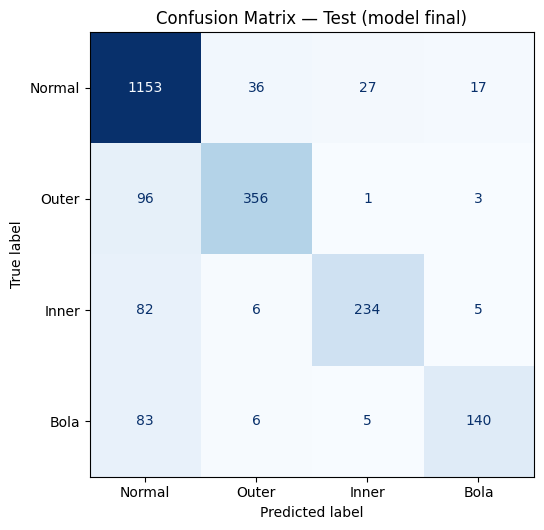

Rekaman kerusakan bola yang diprediksi normal: 83
Recall kelas bola: 0.598


In [ ]:
cm = confusion_matrix(y_test, pred_test_final, labels=labels)
fig, ax = plt.subplots(figsize=(7, 5.4))
ConfusionMatrixDisplay(cm, display_labels=['Normal', 'Outer', 'Inner', 'Bola']).plot(
    ax=ax, cmap='Blues', values_format='d', colorbar=False
)
ax.set_title('Confusion Matrix — Test (model final)')
plt.tight_layout()
fig.savefig(ROOT / 'figures' / 'confusion_matrix_test.png', dpi=160)
plt.show()

print('Rekaman kerusakan bola yang diprediksi normal:', int(cm[labels.index('bola'), labels.index('normal')]))
print('Recall kelas bola:', round(cm[3, 3] / cm[3].sum(), 3))


,feature,importance
15,num__frekuensi_per_putaran,0.198132
12,num__rasio_bpfo,0.085270
7,num__energi_bpfo,0.083015
10,num__frekuensi_dominan_hz,0.076437
13,num__rasio_bpfi,0.074933
5,num__kurtosis,0.064579
14,num__rasio_bsf,0.060247
8,num__energi_bpfi,0.049353
2,num__suhu_housing_C,0.045526
9,num__energi_bsf,0.039142


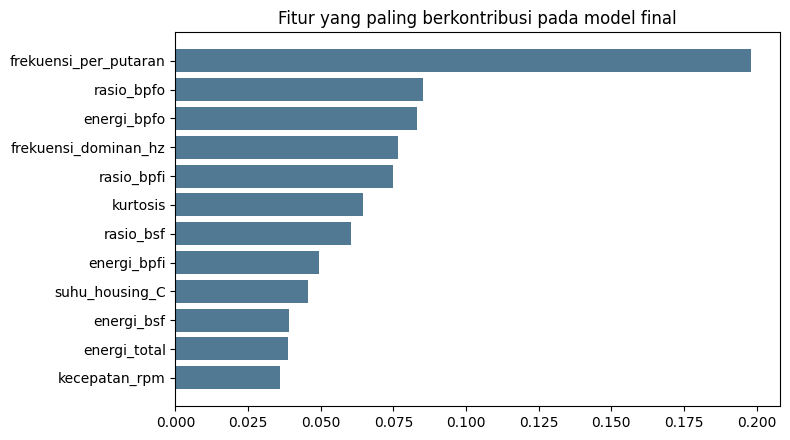

In [ ]:
import sklearn

model_path = ROOT / 'artifacts' / 'model.joblib'
baseline_path = ROOT / 'artifacts' / 'baseline.joblib'
joblib.dump(final_model, model_path, compress=3)
joblib.dump(baseline_final, baseline_path, compress=3)

preprocessor = final_model.named_steps['preprocessor']
feature_names = preprocessor.get_feature_names_out()
estimator = final_model.named_steps['model']
if hasattr(estimator, 'feature_importances_'):
    importances = estimator.feature_importances_
else:
    importances = np.abs(estimator.coef_).mean(axis=0)
importance_df = (pd.DataFrame({'feature': feature_names, 'importance': importances})
                 .sort_values('importance', ascending=False))
importance_df.to_csv(ROOT / 'artifacts' / 'feature_importance.csv', index=False)
display(importance_df.head(12))

fig, ax = plt.subplots(figsize=(8, 4.5))
top = importance_df.head(12).iloc[::-1]
ax.barh(top['feature'].str.replace('num__', '', regex=False).str.replace('cat__', '', regex=False),
        top['importance'], color='#527993')
ax.set_title('Fitur yang paling berkontribusi pada model final')
plt.tight_layout()
fig.savefig(ROOT / 'figures' / 'feature_importance.png', dpi=160)
plt.show()


## 8. Save Model

Model, informasi fitur, dan hasil evaluasi disimpan untuk digunakan pada aplikasi prediksi.

In [ ]:
raw_issues = {
    'rows_raw': len(raw),
    'exact_duplicates': int(raw.duplicated().sum()),
    'rows_clean': len(clean),
    'missing_suhu': int(clean['suhu_housing_C'].isna().sum()),
    'missing_kurtosis': int(clean['kurtosis'].isna().sum()),
    'rpm_zero_or_negative': int((clean['kecepatan_rpm'] <= 0).sum()),
    'rms_zero_or_negative': int((clean['rms_g'] <= 0).sum()),
    'unique_ids': int(clean['id_rekaman'].nunique()),
    'class_counts': {k: int(v) for k, v in clean['kondisi'].value_counts().items()}
}

metadata = {
    'version': '1.0.0',
    'project': 'Kasus 04 - Diagnosis Kerusakan Bearing',
    'selected_model': best_name,
    'labels': labels,
    'display_labels': DISPLAY_LABELS,
    'features_input': RAW_FEATURES,
    'features_engineered': ENGINEERED_COLUMNS if best_uses_engineering else [],
    'engineered_features': bool(best_uses_engineering),
    'threshold': 'not applicable (4-class argmax)',
    'split': {'seed': 42, 'train': len(train), 'validation': len(valid), 'test': len(test),
              'approach': 'stratified random 70/15/15; deduplicate before splitting'},
    'validation_results': results,
    'test_results': test_results,
    'test_classification_report': classification_report(
        y_test, pred_test_final, labels=labels, output_dict=True, zero_division=0),
    'test_confusion_matrix': cm.tolist(),
    'data_audit': raw_issues,
    'selection_rule': 'max macro F1 on validation only; refit train+validation; evaluate locked models on test once',
    'note': 'Data sintetis; prediksi membantu inspeksi, bukan diagnosis mekanis definitif.',
    'versions': {'sklearn': sklearn.__version__, 'pandas': pd.__version__, 'numpy': np.__version__}
}
meta_path = ROOT / 'artifacts' / 'metadata.json'
meta_path.write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding='utf-8')

print('Model final:', model_path, '| ukuran:', round(model_path.stat().st_size/1024/1024, 2), 'MB')
print('Metadata:', meta_path)
print('Macro F1 test:', test_results[best_name]['macro_f1'])


Model final: /content/BearingCare_Kasus04/artifacts/model.joblib | ukuran: 13.02 MB
Metadata: /content/BearingCare_Kasus04/artifacts/metadata.json
Macro F1 test: 0.79718
